<a href="https://colab.research.google.com/github/GH-Rumi/PCVK26_7_HelmiRR/blob/main/Week06_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
NAMA = 'Helmi Rizqi Ramadhan'
NIM = '244107020107'
print(NAMA, NIM)

Helmi Rizqi Ramadhan 244107020107


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

In [4]:
img = cv.imread('/content/drive/MyDrive/PCVK 2026/Images/mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
def convolution2d(image, kernel, stride, padding):
    image_padded = np.pad(image, [(padding, padding), (padding, padding)], mode='constant', constant_values=0)

    kernel_height, kernel_width = kernel.shape
    padded_height, padded_width = image_padded.shape

    output_height = (padded_height - kernel_height) // stride + 1
    output_width = (padded_width - kernel_width) // stride + 1

    output_image = np.zeros((output_height, output_width), dtype=np.float32)

    # Proses perhitungan konvolusi
    for y in range(0, output_height):
        for x in range(0, output_width):
            y_start = y * stride
            y_end = y_start + kernel_height
            x_start = x * stride
            x_end = x_start + kernel_width

            output_image[y][x] = np.sum(image_padded[y_start:y_end, x_start:x_end] * kernel)

    return output_image

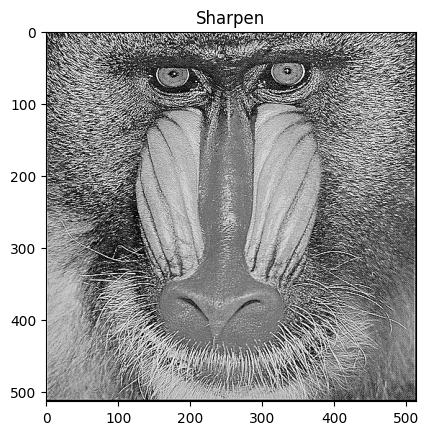

In [5]:
kernel_sharpen = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

hasil_sharpen = convolution2d(img_gray, kernel_sharpen, stride=1, padding=2)

hasil_sharpen = np.clip(hasil_sharpen, 0, 255).astype(np.uint8)

plt.imshow(hasil_sharpen, cmap='gray')
plt.title('Sharpen')
plt.show()

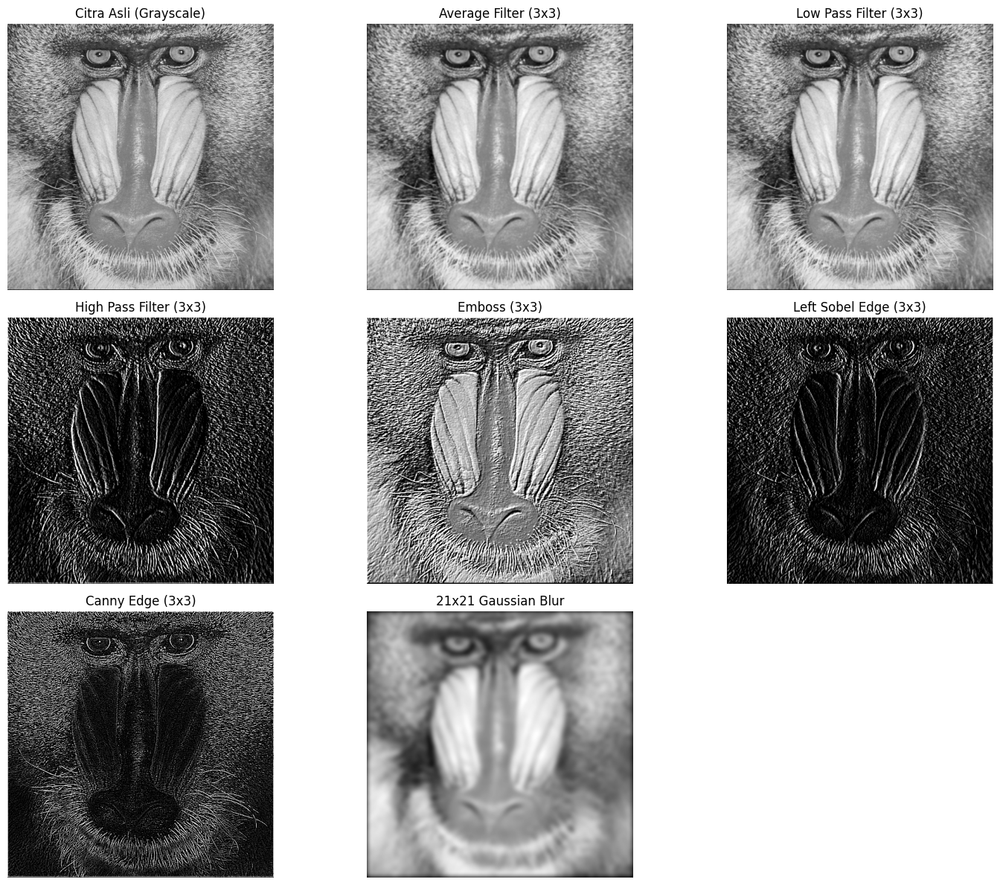

In [6]:
# --- 1. Definisi Semua Kernel ---
kernel_average = np.array([
    [1, 1, 1],
    [1, 1, 1],
    [1, 1, 1]
]) / 9.0

kernel_lowpass = np.array([
    [1, 1, 1],
    [1, 4, 1],
    [1, 1, 1]
]) / 12.0

kernel_highpass = np.array([
    [-1,  0,  1],
    [-1,  0,  3],
    [-3,  0,  1]
])

kernel_emboss = np.array([
    [-2, -1,  0],
    [-1,  1,  1],
    [ 0,  1,  2]
])

kernel_left_sobel = np.array([
    [ 1,  0, -1],
    [ 2,  0, -2],
    [ 1,  0, -1]
])

kernel_canny = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

# 21x21 Gaussian Blur
kernel_size = 21
sigma = math.sqrt(kernel_size)
gaussian_kernel_1d = cv.getGaussianKernel(kernel_size, sigma)
kernel_gaussian = gaussian_kernel_1d @ gaussian_kernel_1d.transpose()

# --- 2. Proses Konvolusi dan Plotting ---
filters = {
    "Average Filter (3x3)": (kernel_average, 1),
    "Low Pass Filter (3x3)": (kernel_lowpass, 1),
    "High Pass Filter (3x3)": (kernel_highpass, 1),
    "Emboss (3x3)": (kernel_emboss, 1),
    "Left Sobel Edge (3x3)": (kernel_left_sobel, 1),
    "Canny Edge (3x3)": (kernel_canny, 1)
}

plt.figure(figsize=(15, 12))

# Plot Citra Asli
plt.subplot(3, 3, 1)
plt.imshow(img_gray, cmap='gray')
plt.title("Citra Asli (Grayscale)")
plt.axis('off')

# Plot hasil filter 3x3
idx = 2
for name, (kernel, padding) in filters.items():
    # Memanggil fungsi convolution2d buatan sendiri
    hasil = convolution2d(img_gray, kernel, stride=1, padding=padding)
    # Normalisasi agar berada dalam rentang piksel valid 0-255
    hasil = np.clip(hasil, 0, 255).astype(np.uint8)

    plt.subplot(3, 3, idx)
    plt.imshow(hasil, cmap='gray')
    plt.title(name)
    plt.axis('off')
    idx += 1

# Plot hasil 21x21 Gaussian Blur (Padding untuk kernel 21x21 adalah 10)
hasil_gaussian = convolution2d(img_gray, kernel_gaussian, stride=1, padding=10)
hasil_gaussian = np.clip(hasil_gaussian, 0, 255).astype(np.uint8)

plt.subplot(3, 3, idx)
plt.imshow(hasil_gaussian, cmap='gray')
plt.title("21x21 Gaussian Blur")
plt.axis('off')

# Merapikan jarak antar subplot dan menampilkannya
plt.tight_layout()
plt.show()

# **Percobaan 1**

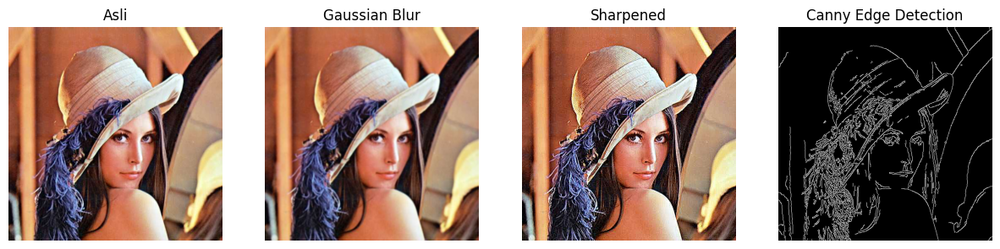

In [7]:
# Fungsi tampil berdampingan
def show_side_by_side(images, titles, figsize=(15,5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        if len(img.shape) == 2:  # grayscale
            plt.subplot(1, len(images), i+1)
            plt.imshow(img, cmap="gray")
        else:  # color
            plt.subplot(1, len(images), i+1)
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

img = cv.imread("/content/drive/MyDrive/PCVK 2026/Images/lena.jpg")
img_gray = cv.cvtColor(img,cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(img, (7,7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)
show_side_by_side([img, blur, sharpened, edges],
                  ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"])

# **Percobaan 2**

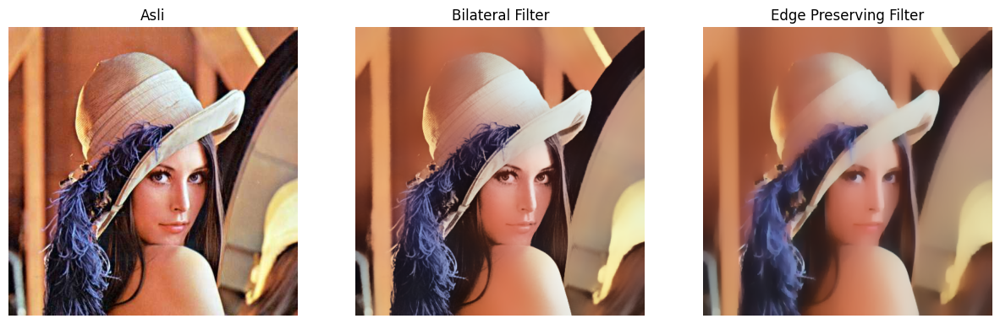

In [8]:
# Filter Modern dari OpenCV
# Bilateral Filter (edge-preserving)
bilateral = cv.bilateralFilter(img, 50, 100, 100)

# Edge Preserving Filter (alternatif Guided Filter)
edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

show_side_by_side([img, bilateral, edge_preserve],
                  ["Asli", "Bilateral Filter", "Edge Preserving Filter"])

# **Percobaan 3**

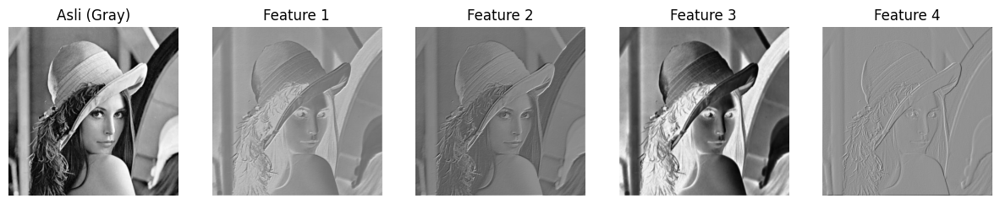

In [9]:
import torch
import torch.nn as nn

# Filter Feature Map yang digunakan pada CNN
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

    def forward(self, x):
        return self.conv1(x)

model = SimpleCNN()

# Ubah gambar ke tensor
img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

# Hasil CNN
with torch.no_grad():
    features = model(img_tensor)

# Visualisasi feature maps
feature_maps = [features[0, i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_gray] + feature_maps,
                  ["Asli (Gray)"] + [f"Feature {i+1}" for i in range(len(feature_maps))])

# **Percobaan 4**

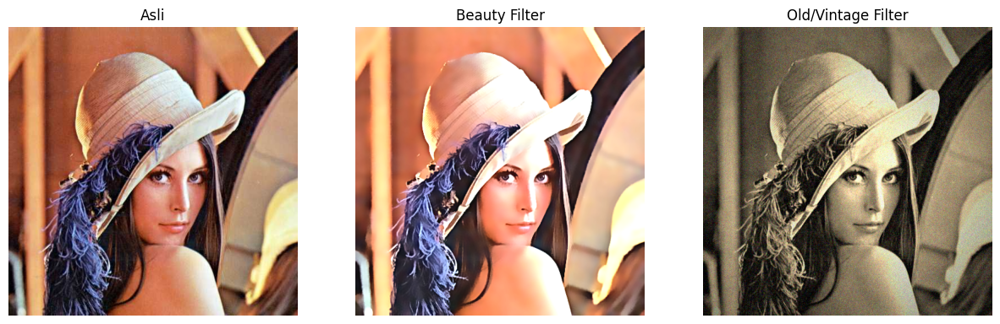

In [10]:
# 1. Beauty Filter
# Step 1: Smoothing kulit dengan bilateral filter
smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)

# Step 2: Unsharp masking (pertajam mata/bibir)
gaussian = cv.GaussianBlur(smooth, (0,0), 3)
sharpened = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)

# Step 3: Brightness & contrast
alpha = 1.2 # contrast
beta = 15 # brightness
beauty = cv.convertScaleAbs(sharpened, alpha=alpha, beta=beta)

# 2. Old/Vintage Filter
# Step 1: Sepia tone
sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])
sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

# Step 2: Vignette
rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols*0.6)
kernel_y = cv.getGaussianKernel(rows, rows*0.6)
kernel = kernel_y * kernel_x.T
mask = kernel / kernel.max()
vignette = np.copy(sepia)
for i in range(3):
    vignette[:,:,i] = vignette[:,:,i] * mask

# Step 3: Noise/Grain
noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)

show_side_by_side([img, beauty, old_img], ["Asli", "Beauty Filter", "Old/Vintage Filter"])

# **Percobaan 5**

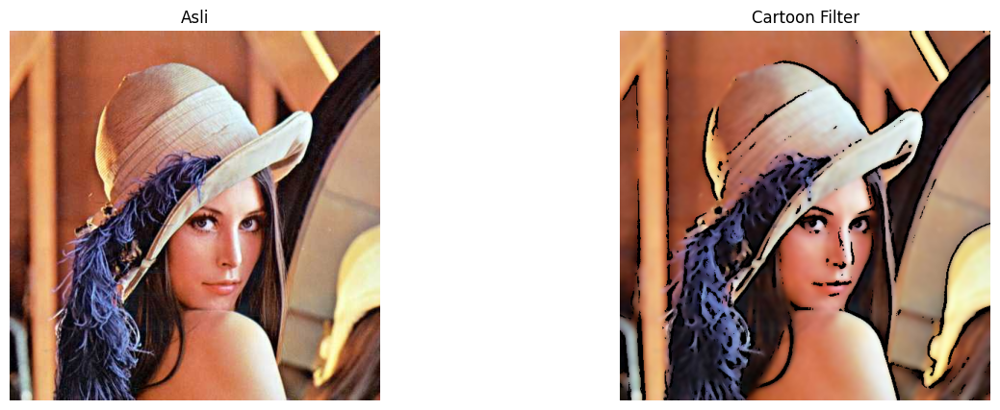

In [11]:
# Filter Anime / Cartoon
# Edge detection (pahat median blur dulu agar gambar menjadi lebih halus)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(gray_blur, 255,
                             cv.ADAPTIVE_THRESH_MEAN_C,
                             cv.THRESH_BINARY, 9, 9)

# Bilateral Filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

# Gabungkan (cartoonize)
cartoon = cv.bitwise_and(color, color, mask=edges)

show_side_by_side([img, cartoon], ["Asli", "Cartoon Filter"])

# **Percobaan 6**

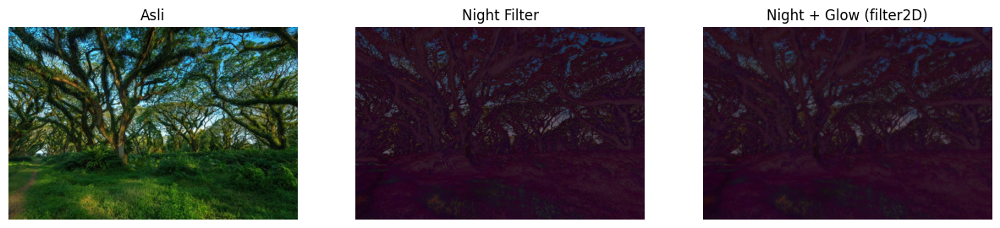

In [12]:
# Night Filter
img_djawatan = cv.imread("/content/drive/MyDrive/PCVK 2026/Images/djawatan.jpg")

# Gelapkan (contrast turun, brightness negatif)
night = cv.convertScaleAbs(img_djawatan, alpha=0.6, beta=-40)

# Tambah bias biru
blue_tint = np.full_like(night, (50, 0, 100)) # BGR
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

# Efek glow di area terang dengan filter2D (blur kernel)
kernel = np.ones((15,15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel)

# Kombinasikan asli + glow
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

show_side_by_side([img_djawatan, night, night_glow],
                  ["Asli", "Night Filter", "Night + Glow (filter2D)"])

# **Percobaan 7**

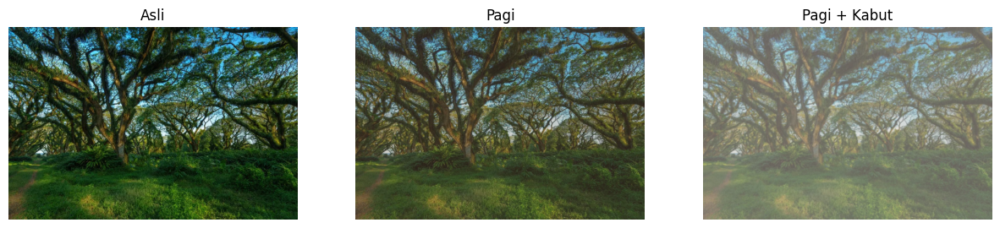

In [13]:
# Filter Suasana Pagi dan Kabut
# Kurangi kontras & cerahkan
alpha = 0.9 # contrast
beta = 20 # brightness
soft = cv.convertScaleAbs(img_djawatan, alpha=alpha, beta=beta)

# Tambahkan warm tone (kemerahan / oranye)
warm_tint = np.full_like(soft, (40, 70, 120)) # BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

# Tambahkan haze (kabut tipis) dengan filter2D
kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T # jadikan 2D kernel
kabut = cv.filter2D(pagi, -1, kernel)

# Tambah layer untuk kabut lebih nyata
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([img_djawatan, pagi, kabut],
                  ["Asli", "Pagi", "Pagi + Kabut"])

# **Tugas 1**

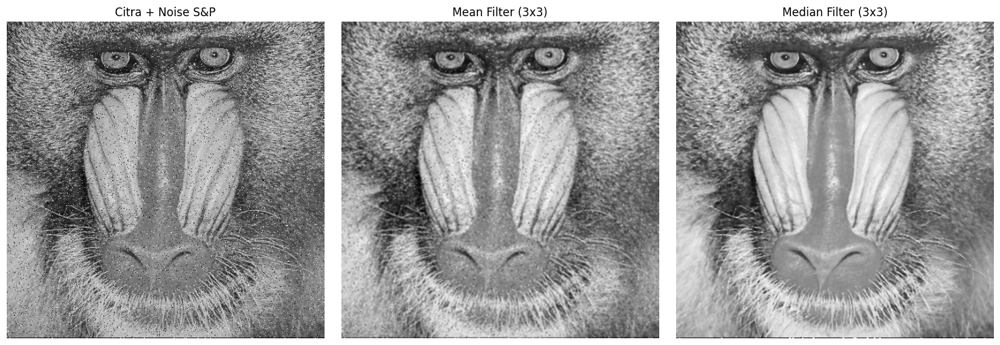

In [16]:
import random

# Membaca citra dalam format grayscale
img_gray = cv.imread('/content/drive/MyDrive/PCVK 2026/Images/mandrill.tiff', cv.IMREAD_GRAYSCALE)

# Pengecekan apakah gambar berhasil diload
if img_gray is None:
    print("Gambar tidak ditemukan! Pastikan path file sudah benar.")
else:
    # Menambahkan Noise bintik hitam-putih (Salt and Pepper)
    img_noise = np.copy(img_gray)
    prob = 0.05  # 5% kemungkinan noise

    for i in range(img_noise.shape[0]):
        for j in range(img_noise.shape[1]):
            rdn = random.random()
            if rdn < prob / 2:
                img_noise[i][j] = 0      # Pepper (bintik hitam)
            elif rdn < prob:
                img_noise[i][j] = 255    # Salt (bintik putih)

    # Terapkan Mean Filter (3x3)
    kernel_mean = np.ones((3, 3), np.float32) / 9.0
    res_mean = cv.filter2D(img_noise, -1, kernel_mean)

    # Terapkan Median Filter (3x3)
    res_median = cv.medianBlur(img_noise, 3)

    # Menampilkan hasil
    plt.figure(figsize=(15, 5))
    images_tugas1 = [img_noise, res_mean, res_median]
    titles_tugas1 = ['Citra + Noise S&P', 'Mean Filter (3x3)', 'Median Filter (3x3)']

    for i in range(3):
        plt.subplot(1, 3, i+1)
        plt.imshow(images_tugas1[i], cmap='gray')
        plt.title(titles_tugas1[i])
        plt.axis('off')

    plt.tight_layout()
    plt.show()

**Analisa**
- Citra Asli : Terdapat banyak noise bintik hitam-putih (Salt & Pepper).   Mean
- Filter : Gagal menghilangkan noise dan justru membuat seluruh gambar menjadi buram kotor, karena nilai ekstrem dari noise ikut dihitung dalam rata-rata.   
- Median Filter : Sangat efektif membersihkan noise dan menjaga ketajaman gambar, karena nilai ekstrem dari noise langsung diabaikan saat filter mengambil nilai tengah (median) piksel.

# **Tugas 2**

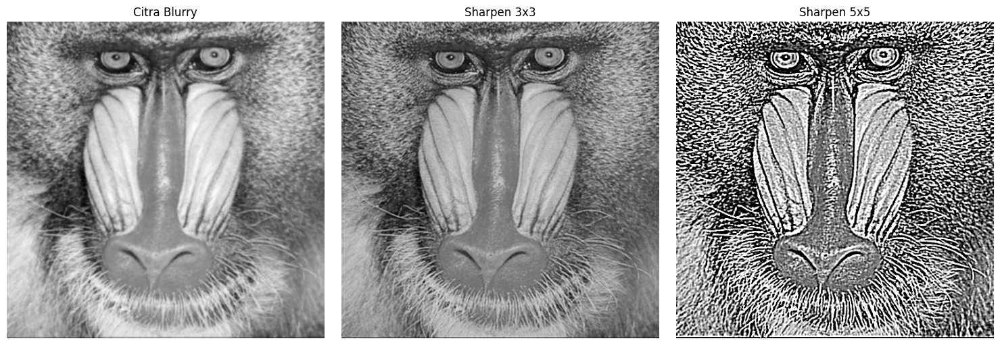

In [17]:
# Membuat citra sedikit buram (blurry) sebagai input simulasi
img_blurry = cv.GaussianBlur(img_gray, (5, 5), 0)

# Buat kernel penajaman 3x3
kernel_sharp_3x3 = np.array([[ 0, -1,  0],
                             [-1,  5, -1],
                             [ 0, -1,  0]])

# Buat kernel penajaman 5x5
kernel_sharp_5x5 = np.array([[-1, -1, -1, -1, -1],
                             [-1, -1, -1, -1, -1],
                             [-1, -1, 25, -1, -1],
                             [-1, -1, -1, -1, -1],
                             [-1, -1, -1, -1, -1]])

# Terapkan filter penajaman pada citra buram
res_sharp_3x3 = cv.filter2D(img_blurry, -1, kernel_sharp_3x3)
res_sharp_5x5 = cv.filter2D(img_blurry, -1, kernel_sharp_5x5)

# Menampilkan hasil evaluasi
plt.figure(figsize=(15, 5))
images_tugas2 = [img_blurry, res_sharp_3x3, res_sharp_5x5]
titles_tugas2 = ['Citra Blurry', 'Sharpen 3x3', 'Sharpen 5x5']

for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.imshow(images_tugas2[i], cmap='gray')
    plt.title(titles_tugas2[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

**Analisa**

- Citra Blurry : Citra ini merupakan gambar masukan dasar (baseline) yang mengalami penurunan kualitas fokus. Terlihat bahwa detail halus seperti tekstur bulu dan garis batas wajah babon tampak memudar, lembut, dan tidak tegas akibat efek pengaburan. Citra ini sengaja digunakan untuk menguji dan mengevaluasi seberapa baik filter spasial dapat memulihkan kejelasan tepi.
- Sharpen 3x3 : Memberikan hasil penajaman yang paling optimal. Filter ini mengembalikan kejelasan tepi dari citra yang buram secara proporsional tanpa memunculkan noise yang mengganggu pandangan.   
- Sharpen 5x5 : Bekerja terlalu agresif dan menghasilkan noise distortion yang sangat ekstrem. Meskipun garis batas menajam, tekstur asli gambar rusak akibat kontras yang berlebihan dan artefak kasar di seluruh area citra.

# **Tugas 3**

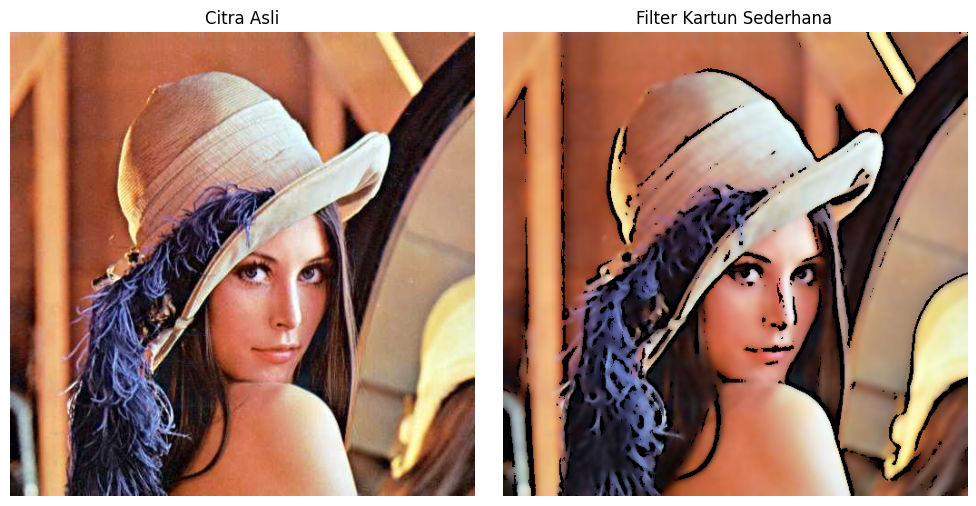

In [19]:
# Membaca citra dan konversi ke RGB
img_color = cv.imread('/content/drive/MyDrive/PCVK 2026/Images/lena.jpg')

# Cek apakah gambar berhasil diload
if img_color is None:
    print("Gambar tidak ditemukan! Pastikan path file sudah benar.")
else:
    img_rgb = cv.cvtColor(img_color, cv.COLOR_BGR2RGB)

    def kartun(image):
        # Penghalusan warna menggunakan Bilateral Filter agar area warna menjadi rata
        color = cv.bilateralFilter(image, d=9, sigmaColor=200, sigmaSpace=200)

        # Deteksi garis tepi menggunakan Adaptive Thresholding
        gray = cv.cvtColor(image, cv.COLOR_RGB2GRAY)
        gray_blur = cv.medianBlur(gray, 7)
        edges = cv.adaptiveThreshold(gray_blur, 255,
                                     cv.ADAPTIVE_THRESH_MEAN_C,
                                     cv.THRESH_BINARY, 9, 9)

        # Penggabungan (kombinasi) menggunakan operasi logika
        cartoon_img = cv.bitwise_and(color, color, mask=edges)

        return cartoon_img

    # Proses pembuatan kartun
    img_kartun = kartun(img_rgb)

    # Tampilkan hasil bersebelahan dengan subplot
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img_rgb)
    plt.title("Citra Asli")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(img_kartun)
    plt.title("Filter Kartun Sederhana")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

**Analisa**
- Citra Asli (Kiri): Menampilkan foto dengan detail warna yang natural, gradasi cahaya yang halus, serta tekstur objek (seperti kulit dan serat topi) yang terlihat jelas dan realistis.   
- Filter Kartun Sederhana (Kanan): Menampilkan citra di mana tekstur dan gradasi warna telah diratakan sehingga tampak seperti blok warna padat. Selain itu, terdapat penambahan garis-garis hitam tebal (outline) yang mempertegas batas-batas objek seperti lekukan wajah, helaian bulu, dan tepi topi, sehingga menciptakan efek visual menyerupai gambar komik dua dimensi.